### Que1.-
In this dataset you have to predict that whether we have to give ATTORNEY to the clients or not (0=Yes, 1=No) based on below factors.
CLMAGE - Age of Client
CLMSEX - Sex of client (0=Male, 1= Female)
SEATBELT - Whether client has Seatbelt or not (0=Yes, 1=No)
CLMINSUR - Whether Client give Insurance or not (0=Yes, 1=No)
LOSS - Loss that client faced

Prepare model by using Decision Tree, Random Forest, AdaBoost, XGBoost & CATBoost & Also calculate Accuracy by confusion matrix, Calculate accuracy score, precision score, recall score, f1 score.

Dataset : Claimants.csv

### Whether we have to give ATTORNEY to the clients or not 
- ** algorithm ** : Naive Bayes, KNN , SVM

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### loading the dataset

In [75]:
df = pd.read_csv("../Datasets/claimants.csv")

#### validating if dataset is successfully read

In [76]:
df.head()

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0,0.0,1.0,0.0,50.0,34.940
1,1,1.0,0.0,0.0,18.0,0.891
2,1,0.0,1.0,0.0,5.0,0.330
3,0,0.0,1.0,1.0,31.0,0.037
4,1,0.0,1.0,0.0,30.0,0.038


#### statical info about data set

In [77]:
df.describe()

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1340.000000,1328.000000,1299.000000,1292.000000,1151.000000,1340.000000
mean,0.488806,0.558735,0.907621,0.017028,28.414422,3.806307
std,0.500061,0.496725,0.289671,0.129425,20.304451,10.636903
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000,0.000000,9.000000,0.400000
50%,0.000000,1.000000,1.000000,0.000000,30.000000,1.069500
75%,1.000000,1.000000,1.000000,0.000000,43.000000,3.781500
max,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


#### checking info of column count , if any null values, and data types of columns

In [78]:
df.info()
# all are of int/float type , no object character type field 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ATTORNEY  1340 non-null   int64  
 1   CLMSEX    1328 non-null   float64
 2   CLMINSUR  1299 non-null   float64
 3   SEATBELT  1292 non-null   float64
 4   CLMAGE    1151 non-null   float64
 5   LOSS      1340 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 62.9 KB


### checking if null values present

In [79]:
df.isna().sum()
#NA values are present 

ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

### filling NA values

In [1]:
df['CLMSEX']=df['CLMSEX'].fillna(df['CLMSEX'].mean())
df['CLMINSUR']=df['CLMINSUR'].fillna(df['CLMINSUR'].mode()[0])
df['SEATBELT']=df['SEATBELT'].fillna(df['SEATBELT'].mode()[0])
df['CLMAGE']=df['CLMAGE'].fillna(df['CLMAGE'].mean())




NameError: name 'df' is not defined

### if i have to segreggate numeric and object type of columns and 

In [82]:
df.isna().sum()

ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

In [83]:
df.corr()
# checking correlation 

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
ATTORNEY,1.000000,0.079321,0.076631,-0.055848,0.009886,-0.219715
CLMSEX,0.079321,1.000000,0.063702,-0.015352,-0.021428,-0.027602
CLMINSUR,0.076631,0.063702,1.000000,0.019953,0.044706,0.004641
SEATBELT,-0.055848,-0.015352,0.019953,1.000000,-0.025379,0.111879
CLMAGE,0.009886,-0.021428,0.044706,-0.025379,1.000000,0.057641
LOSS,-0.219715,-0.027602,0.004641,0.111879,0.057641,1.000000


In [85]:
df.columns

Index(['ATTORNEY', 'CLMSEX', 'CLMINSUR', 'SEATBELT', 'CLMAGE', 'LOSS'], dtype='object')

In [86]:
#sns.pairplot(df)

<Axes: >

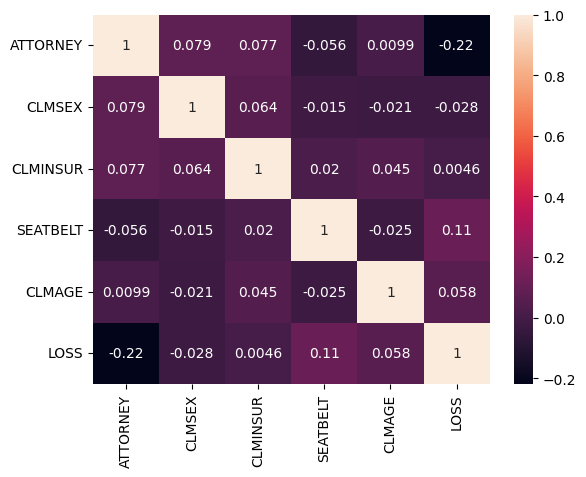

In [87]:
sns.heatmap(df.corr(),annot=True)

In [88]:
df['ATTORNEY'].value_counts()

ATTORNEY
0    685
1    655
Name: count, dtype: int64

#### imbalanced dataset hence , balancing it out

In [89]:
X=df.drop(['ATTORNEY','SEATBELT'],axis=1)
y=df['ATTORNEY']

In [90]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_new,y_new=smote.fit_resample(X,y)

In [91]:
y_new.value_counts()

ATTORNEY
0    685
1    685
Name: count, dtype: int64

#### Splitting the dataset

In [92]:
from sklearn.model_selection import train_test_split
# X_train,X_test,y_train,y_test=train_test_split(X_new,y_new,train_size=0.7,random_state=42)
X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.7,random_state=42)


#### model building 

In [93]:
from sklearn.naive_bayes import GaussianNB

def model_naive_bayes():
    model = GaussianNB()
    model.fit(X_train,y_train)
    return model

In [94]:
from sklearn.svm import SVC
def model_svc():
    model = SVC(C=2,kernel='rbf')
    model.fit(X_train,y_train)
    return model

In [95]:
from sklearn.neighbors import KNeighborsClassifier
def model_knn():
    model= KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train,y_train)
    return model

In [96]:
from xgboost import XGBClassifier

def model_xgb_classibier():
    model = XGBClassifier()
    model.fit(X_train,y_train)
    return model

In [97]:
from catboost import CatBoostClassifier

def model_catboost():
    model = CatBoostClassifier()
    model.fit(X_train,y_train)
    return model

In [98]:
from sklearn.ensemble import RandomForestClassifier

def model_random_forest():
    model = RandomForestClassifier()
    model.fit(X_train,y_train)
    return model

In [99]:
from sklearn.tree import DecisionTreeClassifier

def model_decision_tree():
    model=DecisionTreeClassifier()
    model.fit(X_train,y_train)
    return model

In [100]:
models = [
    {'name':"Naive Bayes","model":model_naive_bayes()},
    {'name':"Support Vector Machine:","model":model_svc()},
    {'name':"K nearest neighbour:","model":model_knn()},
    {'name':"Decision Tree Classifier:","model":model_decision_tree()},
    {'name':"Random Forest Classifier :","model":model_random_forest()},
    {'name':"Cat boost Classifier :","model":model_catboost()},
    {'name':"XGB Classifier :","model":model_xgb_classibier()}
]


Learning rate set to 0.01002
0:	learn: 0.6903993	total: 2.9ms	remaining: 2.9s
1:	learn: 0.6877599	total: 5.1ms	remaining: 2.54s
2:	learn: 0.6855922	total: 6.36ms	remaining: 2.11s
3:	learn: 0.6832710	total: 8.42ms	remaining: 2.1s
4:	learn: 0.6809718	total: 10.7ms	remaining: 2.13s
5:	learn: 0.6787827	total: 13.1ms	remaining: 2.17s
6:	learn: 0.6766974	total: 14.6ms	remaining: 2.07s
7:	learn: 0.6747580	total: 16.7ms	remaining: 2.07s
8:	learn: 0.6726637	total: 18.8ms	remaining: 2.07s
9:	learn: 0.6705273	total: 21.1ms	remaining: 2.09s
10:	learn: 0.6685187	total: 23.1ms	remaining: 2.08s
11:	learn: 0.6663931	total: 25.4ms	remaining: 2.09s
12:	learn: 0.6644628	total: 27.2ms	remaining: 2.07s
13:	learn: 0.6623046	total: 29.4ms	remaining: 2.07s
14:	learn: 0.6606944	total: 30.9ms	remaining: 2.03s
15:	learn: 0.6585967	total: 33.4ms	remaining: 2.05s
16:	learn: 0.6568042	total: 35.5ms	remaining: 2.05s
17:	learn: 0.6550007	total: 37.7ms	remaining: 2.05s
18:	learn: 0.6531359	total: 39.9ms	remaining: 2.0

In [102]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report

def format_metric(metric):
    return f"{metric*100:2f}"

def evaluation_model(models_info):
    name=models_info['name']
    model=models_info['model']

    y_pred = model.predict(X_test)
    # accuracy=f"{accuracy_score(y_test,y_pred) * 100:.2f}"
    
    accuracy=format_metric(accuracy_score(y_test,y_pred))
    precision=format_metric(precision_score(y_test,y_pred))
    recall=format_metric(recall_score(y_test,y_pred))
    f1=format_metric(f1_score(y_test,y_pred))
    # classification_report= classification_report(y_test,y_pred)

    return accuracy,precision,recall,f1 
    

#### for loop to access info about one one model 

In [103]:
evaluation_result=[]  

for value in models:
    accuracy,precision,recall,f1  = evaluation_model(value)

    evaluation_result.append(
        {
            'model_name':value['name'],
            'accuracy':accuracy,
            'precision':precision,
            'recall':recall,
            'f1':f1,
        } 
    )

In [104]:
evaluation_result_df = pd.DataFrame(evaluation_result)

In [105]:
evaluation_result_df

,model_name,accuracy,precision,recall,f1
0,Naive Bayes,63.523573,59.000000,88.059701,70.658683
1,Support Vector Machine:,68.982630,65.447154,80.099502,72.035794
2,K nearest neighbour:,65.260546,65.482234,64.179104,64.824121
3,Decision Tree Classifier:,61.290323,62.295082,56.716418,59.375000
4,Random Forest Classifier :,68.982630,71.348315,63.184080,67.018470
5,Cat boost Classifier :,71.464020,72.631579,68.656716,70.588235
6,XGB Classifier :,66.004963,67.582418,61.194030,64.229765
